# Chapter 6 · Learned forecasters

*Book 21 · Time Series · Shelf V*

**Builds on:** [Chapter 5](05-backtesting.ipynb) (honest evaluation), gradient boosting from book
22, and convolutional networks from book 26.
**You will:** frame the day-ahead forecast so that no feature sees the future, train a
gradient-boosted model on lag and calendar features and a small temporal CNN on the raw week,
and compare both with the baselines on a validation year.

Classical models learn a few parameters from one series. Learned forecasters treat forecasting
as supervised learning: every past day becomes a training example. The price is that the
features must be built by hand -- and that is where the future leaks in, if you let it.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance

from ds_toolbox import evaluation as ev
from ds_toolbox import features as ft
from ds_toolbox import forecasting as fc
from ds_toolbox import io, viz

viz.use_style()

## The task, and the grid

Every night at midnight, forecast the 24 hours of the coming day. A model may use everything up
to that midnight and nothing after it.

The cleanest way to keep that promise is a grid: one row per local day, one column per
wall-clock hour. A feature for day $d$ may only come from rows $d-1$ and earlier. The two DST
nights break the grid; `to_local_days` mends them the same way every time (the repeated October
hour is averaged, the missing March hour interpolated).

In [2]:
raw = io.load_sample("ewz_zurich_hourly.csv.gz")
hourly = raw.assign(t=pd.to_datetime(raw["hour_utc"], utc=True)).set_index("t")["total_mwh"]
grid = ft.to_local_days(hourly)
holidays = ft.swiss_holidays(range(grid.index.year.min(), grid.index.year.max() + 1))
print(grid.shape, "|", grid.index[0].date(), "->", grid.index[-1].date())

(3599, 24) | 2017-01-01 -> 2026-11-08


**The protocol.** The last 365 days are the *test year* -- the challenge reports on them and
nothing in this chapter touches them. The year before is the *validation year*, where we compare
and choose. Everything before is training.

In [3]:
test_start = grid.index[-365]
val_start = grid.index[-730]
print("train until", (val_start - pd.Timedelta(days=1)).date(), "| validation", val_start.date(),
      "->", (test_start - pd.Timedelta(days=1)).date(), "| test (untouched)", test_start.date(), "->")
dev = grid[grid.index < test_start]

train until 2024-11-08 | validation 2024-11-09 -> 2025-11-08 | test (untouched) 2025-11-09 ->


## The baselines to beat

"Yesterday" and "the same day last week", both read straight off the grid.

In [4]:
val = dev[dev.index >= val_start]
yesterday = dev.shift(1).loc[val.index]
last_week = dev.shift(7).loc[val.index]
scores = {"yesterday": ev.mae(val, yesterday), "same day last week": ev.mae(val, last_week)}
scores

{'yesterday': 19.942886757990866, 'same day last week': 13.592766438356163}

## Gradient boosting on lag and calendar features

`day_ahead_table` turns the grid into one row per hour with features known at the previous
midnight: lags of 24, 48, 168 and 336 hours, yesterday's mean and last hour, last week's mean,
and the calendar with the Zurich holidays. The toolbox's `lag_features` refuses any lag shorter
than the 24-hour lead time -- the leak that would make this model look much better than it is.

In [5]:
X, y = fc.day_ahead_table(dev, holidays)
is_val = X.index >= val_start
gbm = HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, random_state=0)
gbm.fit(X[~is_val], y[~is_val])
gbm_val = pd.Series(gbm.predict(X[is_val]), index=X.index[is_val])
scores["gradient boosting"] = ev.mae(y[is_val], gbm_val)
print(f"{X.shape[1]} features | trained on {(~is_val).sum()} hours")

14 features | trained on 68520 hours


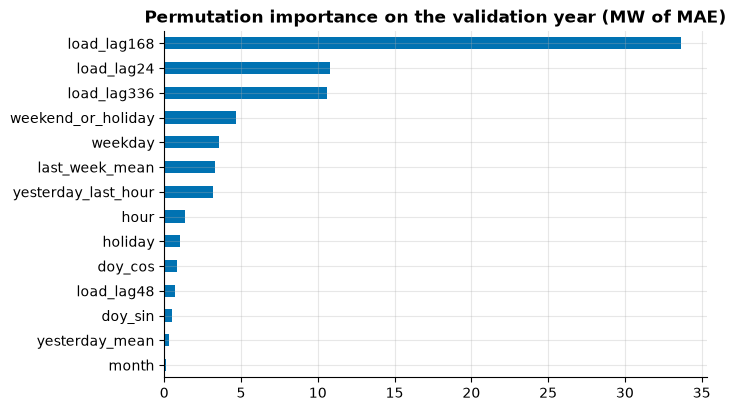

In [6]:
sample = X[is_val].sample(4000, random_state=0)
imp = permutation_importance(gbm, sample, y.loc[sample.index], n_repeats=3, random_state=0,
                             scoring="neg_mean_absolute_error")
pd.Series(imp.importances_mean, index=X.columns).sort_values().plot.barh(
    figsize=(7, 4.5), title="Permutation importance on the validation year (MW of MAE)");

## A temporal CNN on the raw week

No hand-made features this time. The network reads the last 168 hours as a signal, passes it
through three dilated 1-D convolutions (they see 7, 19 and 43 hours at once), and a dense layer
adds the day's calendar. It predicts a *correction* to "the same day last week" in that
residual's own units, starting from zero: at initialisation it *is* the baseline, and training
can only earn its way away from it.

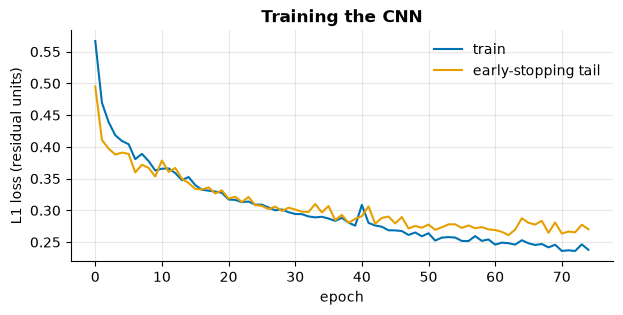

In [7]:
w = fc.cnn_windows(dev, holidays)
dates = pd.DatetimeIndex(w["dates"])
train_w = {k: v[dates < val_start] for k, v in w.items()}
val_w = {k: v[dates >= val_start] for k, v in w.items()}
cnn = fc.CNNForecaster(epochs=80, val_days=180, patience=12, seed=0).fit(train_w)
cnn_val = cnn.predict(val_w)
scores["temporal CNN"] = ev.mae(val_w["y"], cnn_val)

hist = np.array(cnn.history)
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(hist[:, 0], label="train")
ax.plot(hist[:, 1], label="early-stopping tail")
ax.set(xlabel="epoch", ylabel="L1 loss (residual units)", title="Training the CNN")
ax.legend();

## On the validation year

,MAE (MW),skill vs last week
gradient boosting,6.193,0.544
temporal CNN,6.291,0.537
same day last week,13.593,0.000
yesterday,19.943,-0.467


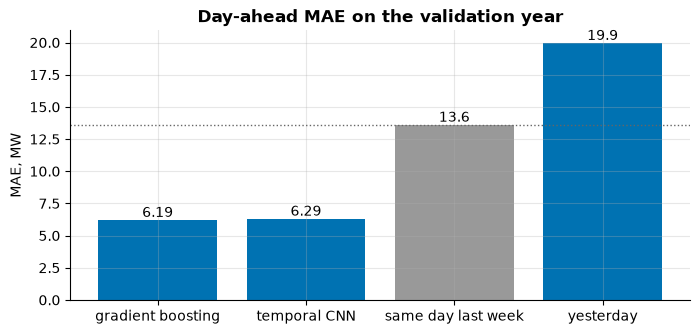

In [8]:
board = pd.Series(scores).sort_values()
fig, ax = plt.subplots(figsize=(8, 3.5))
viz.bar_scores(board.to_dict(), baseline="same day last week", ax=ax, unit="MAE, MW",
               title="Day-ahead MAE on the validation year")
pd.DataFrame({"MAE (MW)": board, "skill vs last week": [ev.skill(v, scores["same day last week"])
                                                        for v in board]}).round(3)

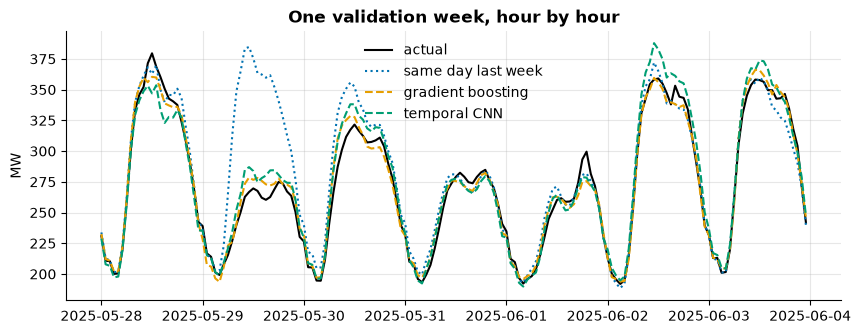

In [9]:
week = slice(val.index[200], val.index[206])
days = val.loc[week].index
actual = ft.from_local_days(val.loc[week])
gbm_week = gbm_val[(gbm_val.index >= days[0]) & (gbm_val.index < days[-1] + pd.Timedelta(days=1))]
cnn_week = pd.Series(cnn_val[np.isin(val_w["dates"], days.to_numpy())].reshape(-1), index=actual.index)
lw_week = ft.from_local_days(last_week.loc[week])
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(actual, color="black", lw=1.5, label="actual")
ax.plot(lw_week, ls=":", label="same day last week")
ax.plot(gbm_week, ls="--", label="gradient boosting")
ax.plot(cnn_week, ls="--", label="temporal CNN")
ax.set(ylabel="MW", title="One validation week, hour by hour")
ax.legend();

Thursday 29 May 2025 was Ascension Day, a public holiday. "The same day last week" forecasts
a working Thursday and misses by almost 100 MW at noon; both learned models know the holiday
and stay close.

Read the importance plot before trusting the score. The model leans hardest on the same hour a
week ago, then a day and two weeks ago, then on the calendar -- the weekly pattern of chapter 2,
corrected by what the calendar knows. A leak would show up here first, as a feature that should
not be able to explain that much.

## What to remember

- Frame the task first: what is known at the moment of the forecast. Then build features.
- Keep a test period nobody touches; choose on a validation period before it.
- Learning a correction to a strong baseline is easier than learning the level.

## Exercises

1. Drop the holiday flag. Which days get worse, and by how much?
2. Add a lag of 23 hours to `day_ahead_table` and watch `lag_features` refuse it. Then think about
   which target hours *could* legitimately use it.
3. Give the CNN two weeks of input instead of one. Does it help?

**Next:** [The challenge · swiss-forecast](challenge/swiss-forecast.ipynb)